# Bank marketing model - FINAL v2 (use this one, NOT v1!!)

Predicts if a client will subscribe to a term deposit after a sales call.

Last run on Kasun's laptop. **Don't change anything below, it works.**

In [1]:
import os, sys, pickle, zipfile, io, urllib.request
import warnings
warnings.filterwarnings('ignore')   # too many warnings
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, roc_auc_score
from xgboost import XGBClassifier

In [2]:
# download the data if we don't have it (copied from stackoverflow)
if not os.path.exists('bank-additional-full.csv'):
    z = zipfile.ZipFile(io.BytesIO(urllib.request.urlopen(
        'https://archive.ics.uci.edu/static/public/222/bank+marketing.zip').read()))
    inner = zipfile.ZipFile(io.BytesIO(z.read('bank-additional.zip')))
    open('bank-additional-full.csv', 'wb').write(
        inner.read('bank-additional/bank-additional-full.csv'))
df = pd.read_csv('bank-additional-full.csv', sep=';')
print(df.shape)
df.head()

(41188, 21)


,age,job,marital,education,default,housing,loan,contact,month,day_of_week,...,campaign,pdays,previous,poutcome,emp.var.rate,cons.price.idx,cons.conf.idx,euribor3m,nr.employed,y
0,56,housemaid,married,basic.4y,no,no,no,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
1,57,services,married,high.school,unknown,no,no,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
2,37,services,married,high.school,no,yes,no,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
3,40,admin.,married,basic.6y,no,no,no,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
4,56,services,married,high.school,no,no,yes,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no


In [3]:
df['y'] = df['y'].map({'yes': 1, 'no': 0})
df = pd.get_dummies(df, drop_first=True)   # encode everything
X = df.drop(columns=['y'])
y = df['y']
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=1)

In [4]:
model = XGBClassifier(n_estimators=300, max_depth=6, learning_rate=0.1)  # tuned by hand on friday
model.fit(X_train, y_train)

,"base_score base_score: typing.Union[float, typing.List[float], NoneType]The initial prediction score of all instances, global bias.",None
,booster,None
,"callbacks callbacks: typing.Optional[typing.List[xgboost.callback.TrainingCallback]]List of callback functions that are applied at end of each iteration.It is possible to use predefined callbacks by using:ref:`Callback API <callback_api>`... note:: States in callback are not preserved during training, which means callback objects can not be reused for multiple training sessions without reinitialization or deepcopy... code-block:: python for params in parameters_grid: # be sure to (re)initialize the callbacks before each run callbacks = [xgb.callback.LearningRateScheduler(custom_rates)] reg = xgboost.XGBRegressor(**params, callbacks=callbacks) reg.fit(X, y)",None
,colsample_bylevel colsample_bylevel: typing.Optional[float]Subsample ratio of columns for each level.,None
,colsample_bynode colsample_bynode: typing.Optional[float]Subsample ratio of columns for each split.,None
,colsample_bytree colsample_bytree: typing.Optional[float]Subsample ratio of columns when constructing each tree.,None
,"device device: typing.Optional[str].. versionadded:: 2.0.0Device ordinal, available options are `cpu`, `cuda`, and `gpu`.",None
,"early_stopping_rounds early_stopping_rounds: typing.Optional[int].. versionadded:: 1.6.0- Activates early stopping. Validation metric needs to improve at least once in every **early_stopping_rounds** round(s) to continue training. Requires at least one item in **eval_set** in :py:meth:`fit`.- If early stopping occurs, the model will have two additional attributes: :py:attr:`best_score` and :py:attr:`best_iteration`. These are used by the :py:meth:`predict` and :py:meth:`apply` methods to determine the optimal number of trees during inference. If users want to access the full model (including trees built after early stopping), they can specify the `iteration_range` in these inference methods. In addition, other utilities like model plotting can also use the entire model.- If you prefer to discard the trees after `best_iteration`, consider using the callback function :py:class:`xgboost.callback.EarlyStopping`.- If there's more than one item in **eval_set**, the last entry will be used for early stopping. If there's more than one metric in **eval_metric**, the last metric will be used for early stopping.",None
,enable_categorical enable_categorical: boolSee the same parameter of :py:class:`DMatrix` for details.,True
,"eval_metric eval_metric: typing.Union[str, typing.List[typing.Union[str, typing.Callable]], typing.Callable, NoneType].. versionadded:: 1.6.0Metric used for monitoring the training result and early stopping. It can be astring or list of strings as names of predefined metric in XGBoost (See:doc:`/parameter`), one of the metrics in :py:mod:`sklearn.metrics`, or anyother user defined metric that looks like `sklearn.metrics`.If custom objective is also provided, then custom metric should implement thecorresponding reverse link function.Unlike the `scoring` parameter commonly used in scikit-learn, when a callableobject is provided, it's assumed to be a cost function and by default XGBoostwill minimize the result during early stopping.For advanced usage on Early stopping like directly choosing to maximize insteadof minimize, see :py:obj:`xgboost.callback.EarlyStopping`.See :doc:`/tutorials/custom_metric_obj` and :ref:`custom-obj-metric` for moreinformation... code-block:: python from sklearn.datasets import load_diabetes from sklearn.metrics import mean_absolute_error X, y = load_diabetes(return_X_y=True) reg = xgb.XGBRegressor( tree_method=""hist"", eval_metric=mean_absolute_error, ) reg.fit(X, y, eval_set=[(X, y)])",None
,feature_types feature_types: typing.Optional[typing.Sequence[str]].. versionadded:: 1.7.0Used for specifying feature types without constructing a dataframe. Seethe :py:class:`DMatrix` for details.,None


In [5]:
pred = model.predict(X_test)
prob = model.predict_proba(X_test)[:, 1]
print('Accuracy:', round(accuracy_score(y_test, pred), 3))
print('ROC AUC: ', round(roc_auc_score(y_test, prob), 3))
# amazing!!! ship it

Accuracy: 0.914
ROC AUC:  0.948


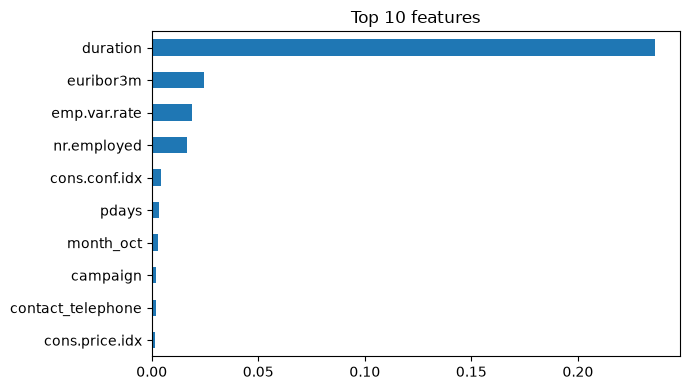

In [6]:
# which features matter most? (how much AUC drops when a column is shuffled)
from sklearn.inspection import permutation_importance
r = permutation_importance(model, X_test, y_test, scoring='roc_auc', n_repeats=3, random_state=0)
imp = pd.Series(r.importances_mean, index=X.columns).sort_values().tail(10)
imp.plot.barh(figsize=(7, 4), title='Top 10 features')
plt.tight_layout()
plt.show()

In [7]:
pickle.dump(model, open('model_final_v2_REAL.pkl', 'wb'))
print('saved model_final_v2_REAL.pkl - emailed to the engineering team')

saved model_final_v2_REAL.pkl - emailed to the engineering team


In [8]:
X2_train = X_train.drop(columns=['duration'])
X2_test = X_test.drop(columns=['duration'])
model2 = XGBClassifier(n_estimators=300, max_depth=6, learning_rate=0.1).fit(X2_train, y_train)
print('ROC AUC with duration:   ', round(roc_auc_score(y_test, prob), 3))
print('ROC AUC without duration:', round(roc_auc_score(y_test, model2.predict_proba(X2_test)[:, 1]), 3))

ROC AUC with duration:    0.948
ROC AUC without duration: 0.794
